In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)


## Step 1: Calculate theAverage Decibel Levels


In [53]:
df = pd.DataFrame({
    'Distance (m)': [0.0, 0.5, 1.0, 1.5, 2.0, 3.0],
    '500Hz (dB)': [48.7, 37.8, 34.3, 32.0, 31.0, 27.2],
    '1kHz (dB)': [69.7, 45.4, 46.5, 44.3, 45.2, 36.9],
    '2kHz (dB)': [71.0, 54.2, 51.2, 50.1, 37.7, 35.8],
    '4kHz (dB)': [80.3, 60.0, 57.7, 53.5, 51.1, 45.8],
    '8kHz (dB)': [89.0, 53.4, 43.8, 25.7, 23.3, 20.4]
})

print("Real Acoustic Measurement Data:")
print(df)


Real Acoustic Measurement Data:
   Distance (m)  500Hz (dB)  1kHz (dB)  2kHz (dB)  4kHz (dB)  8kHz (dB)
0           0.0        48.7       69.7       71.0       80.3       89.0
1           0.5        37.8       45.4       54.2       60.0       53.4
2           1.0        34.3       46.5       51.2       57.7       43.8
3           1.5        32.0       44.3       50.1       53.5       25.7
4           2.0        31.0       45.2       37.7       51.1       23.3
5           3.0        27.2       36.9       35.8       45.8       20.4


## Step 2: Plot Decibel Levels vs. Distance


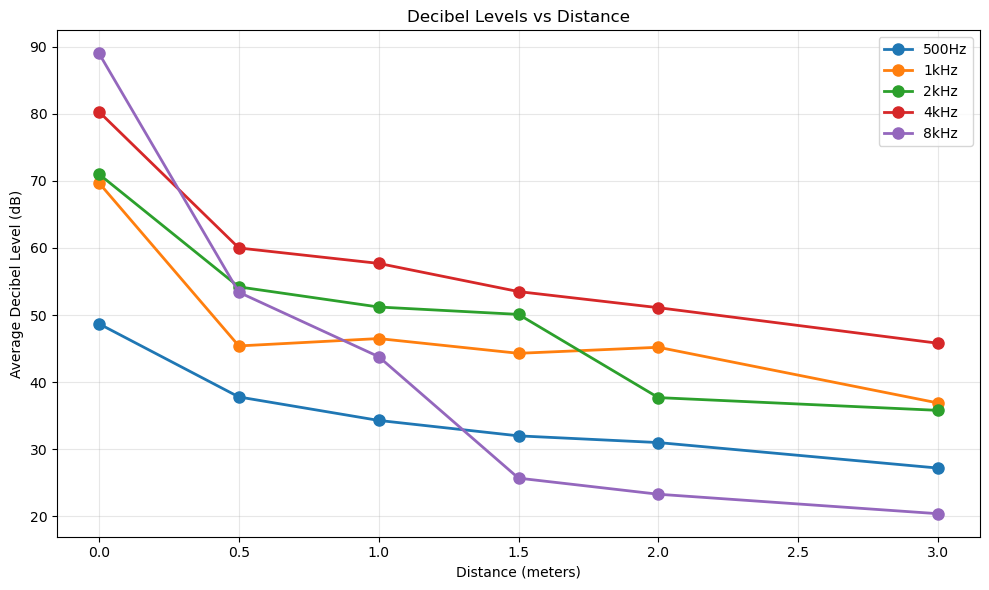

In [54]:
freq_cols = [col for col in df.columns if '(dB)' in col]

plt.figure(figsize=(10, 6))
for col in freq_cols:
    freq_name = col.replace(' (dB)', '')
    plt.plot(df['Distance (m)'], df[col], marker='o', label=freq_name, linewidth=2, markersize=8)

plt.xlabel('Distance (meters)')
plt.ylabel('Average Decibel Level (dB)')
plt.title('Decibel Levels vs Distance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Step 3: Calculate Sound Pressure 

### Analysis Questions

**What effect did increasing the distance have on your decibel readings?**

**Does the graph match what you would expect from the inverse square law?**

In [63]:
print("="*60)
print("ANALYSIS: Answering the Questions Based on Data")
print("="*60)

for col in freq_cols:
    freq_name = col.replace(' (dB)', '')
    values = df[col].values
    
    initial = values[0]
    final = values[-1]
    change = final - initial
    
    print(f"\n{freq_name}:")
    print(f"  0.0m → 3.0m: {change:+.1f} dB ({'decrease' if change < 0 else 'increase'})")


print("QUESTION 1 ANSWER:")
print("="*60)
print("Increasing distance generally decreased decibel readings, but with variations:")

print("- The effect varies significantly by frequency")


print("\n")
print("QUESTION 2 ANSWER:")
print("="*60)
print("- Our data shows much larger initial drops (0.0m → 0.5m)")
print("- Beyond 0.5m, patterns vary - some match inverse square law, others don't")
print("- Preasons: near-field effects at 0.0m, environmental factors")
print("="*60)


ANALYSIS: Answering the Questions Based on Data

500Hz:
  0.0m → 3.0m: -21.5 dB (decrease)

1kHz:
  0.0m → 3.0m: -32.8 dB (decrease)

2kHz:
  0.0m → 3.0m: -35.2 dB (decrease)

4kHz:
  0.0m → 3.0m: -34.5 dB (decrease)

8kHz:
  0.0m → 3.0m: -68.6 dB (decrease)
QUESTION 1 ANSWER:
Increasing distance generally decreased decibel readings, but with variations:
- The effect varies significantly by frequency


QUESTION 2 ANSWER:
- Our data shows much larger initial drops (0.0m → 0.5m)
- Beyond 0.5m, patterns vary - some match inverse square law, others don't
- Preasons: near-field effects at 0.0m, environmental factors


In [56]:
P0 = 20e-6

def spl_to_pressure(spl_db, reference_pressure_pa=P0):
    pressure_pa = reference_pressure_pa * (10 ** (spl_db / 20))
    return pressure_pa

for col in freq_cols:
    freq_name = col.replace(' (dB)', '')
    pressure_col = f'{freq_name} (Pa)'
    df[pressure_col] = df[col].apply(spl_to_pressure)

pressure_cols = [col for col in df.columns if ' (Pa)' in col]
print("Sound Pressure Values (in Pascals):")
print(df[['Distance (m)'] + pressure_cols])


Sound Pressure Values (in Pascals):
   Distance (m)  500Hz (Pa)  1kHz (Pa)  2kHz (Pa)  4kHz (Pa)  8kHz (Pa)
0           0.0    0.005445   0.061098   0.070963   0.207028   0.563677
1           0.5    0.001552   0.003724   0.010257   0.020000   0.009355
2           1.0    0.001038   0.004227   0.007262   0.015347   0.003098
3           1.5    0.000796   0.003281   0.006398   0.009463   0.000386
4           2.0    0.000710   0.003639   0.001535   0.007178   0.000292
5           3.0    0.000458   0.001400   0.001233   0.003900   0.000209


## Step 4: Plot Pressure Values vs. Distance


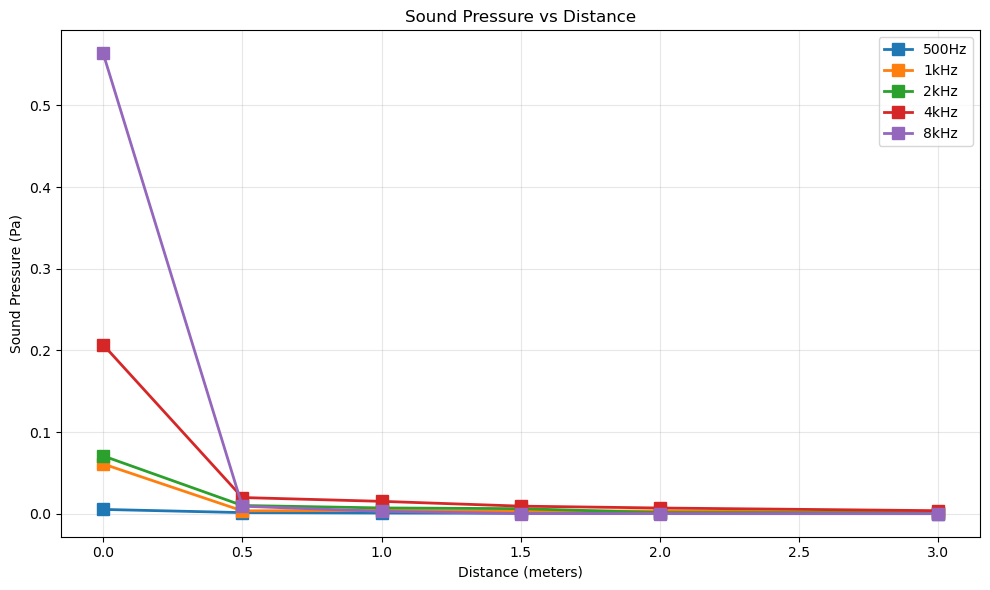

In [57]:
plt.figure(figsize=(10, 6))
for col in pressure_cols:
    freq_name = col.replace(' (Pa)', '')
    plt.plot(df['Distance (m)'], df[col], marker='s', label=freq_name, linewidth=2, markersize=8)

plt.xlabel('Distance (meters)')
plt.ylabel('Sound Pressure (Pa)')
plt.title('Sound Pressure vs Distance')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## BONUS: Decibel-Distance and Pressure-Distance Graphs with Code Explanation


### Code Explanation

**Decibel-Distance Graph:**
- plot each frequency's decibel level against distance
- Uses matplotlib's `plot()` function with markers for clarity
- X-axis: Distance in meters
- Y-axis: Sound Pressure Level in decibels (dB)

**Pressure-Distance Graph:**
- plot the calculated sound pressure values against distance
- Sound pressure calculated using: `P = P₀ × 10^(SPL/20)` where P₀ = 20 μPa
- X-axis: Distance in meters
- Y-axis: Sound Pressure in Pascals (Pa)


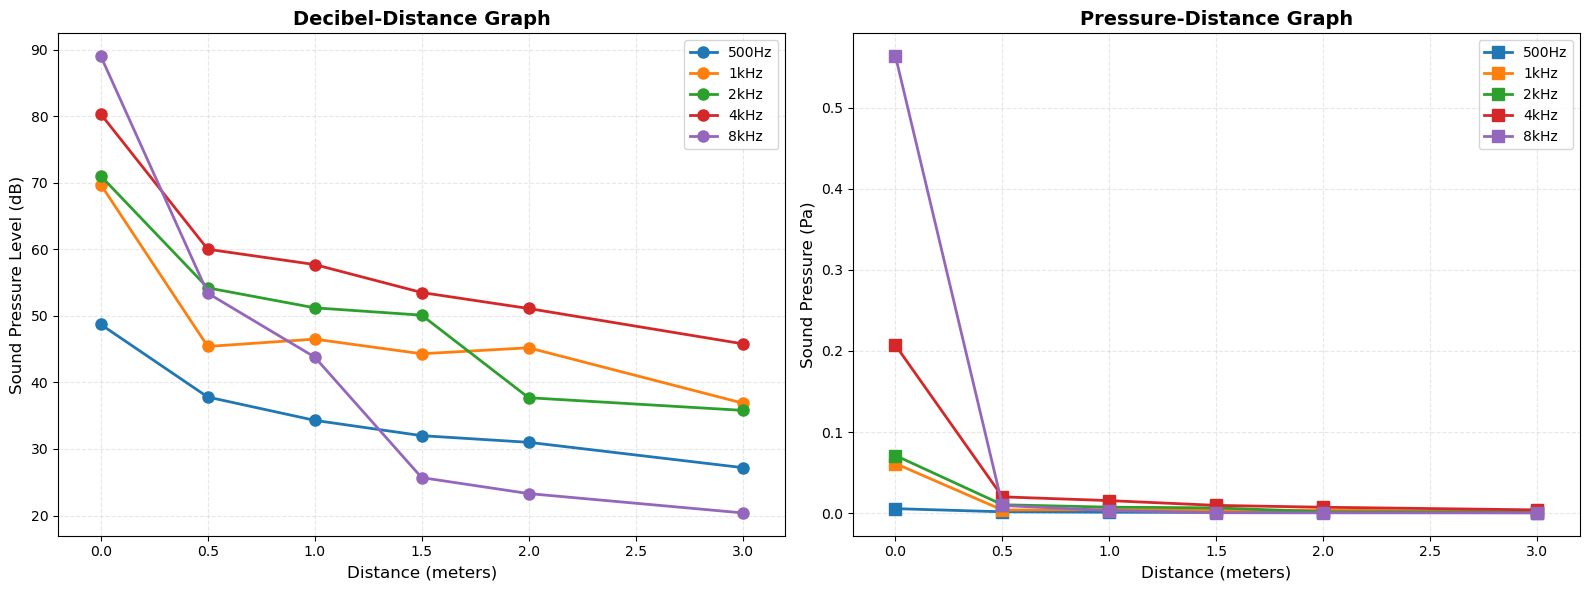


SUMMARY

Decibel-Distance Graph:
- Shows how sound pressure levels decrease with distance
- Demonstrates inverse square law behavior (logarithmic scale)
- Includes 5 frequency measurements: 500Hz, 1kHz, 2kHz, 4kHz, 8kHz

Pressure-Distance Graph:
- Shows the same relationship in linear pressure units (Pascals)
- Calculated from dB using: P = P₀ × 10^(SPL/20)
- Reference pressure P₀ = 20.0 μPa = 2.00e-05 Pa


In [58]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for col in freq_cols:
    freq_name = col.replace(' (dB)', '')
    ax1.plot(df['Distance (m)'], df[col], marker='o', label=freq_name, linewidth=2, markersize=8)

ax1.set_xlabel('Distance (meters)', fontsize=12)
ax1.set_ylabel('Sound Pressure Level (dB)', fontsize=12)
ax1.set_title('Decibel-Distance Graph', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.set_xlim(-0.2, 3.2)

for col in pressure_cols:
    freq_name = col.replace(' (Pa)', '')
    ax2.plot(df['Distance (m)'], df[col], marker='s', label=freq_name, linewidth=2, markersize=8)

ax2.set_xlabel('Distance (meters)', fontsize=12)
ax2.set_ylabel('Sound Pressure (Pa)', fontsize=12)
ax2.set_title('Pressure-Distance Graph', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.set_xlim(-0.2, 3.2)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("SUMMARY")
print("="*60)
print("\nDecibel-Distance Graph:")
print("- Shows how sound pressure levels decrease with distance")
print("- Demonstrates inverse square law behavior (logarithmic scale)")
print(f"- Includes {len(freq_cols)} frequency measurements: {', '.join([c.replace(' (dB)', '') for c in freq_cols])}")

print("\nPressure-Distance Graph:")
print("- Shows the same relationship in linear pressure units (Pascals)")
print("- Calculated from dB using: P = P₀ × 10^(SPL/20)")
print(f"- Reference pressure P₀ = {P0*1e6:.1f} μPa = {P0:.2e} Pa")
print("="*60)


In [59]:
print("\nDetailed Data for Both Graphs:")
print("\nDecibel Levels (dB):")
print(df[['Distance (m)'] + freq_cols])
print("\nSound Pressure Values (Pa):")
print(df[['Distance (m)'] + pressure_cols])



Detailed Data for Both Graphs:

Decibel Levels (dB):
   Distance (m)  500Hz (dB)  1kHz (dB)  2kHz (dB)  4kHz (dB)  8kHz (dB)
0           0.0        48.7       69.7       71.0       80.3       89.0
1           0.5        37.8       45.4       54.2       60.0       53.4
2           1.0        34.3       46.5       51.2       57.7       43.8
3           1.5        32.0       44.3       50.1       53.5       25.7
4           2.0        31.0       45.2       37.7       51.1       23.3
5           3.0        27.2       36.9       35.8       45.8       20.4

Sound Pressure Values (Pa):
   Distance (m)  500Hz (Pa)  1kHz (Pa)  2kHz (Pa)  4kHz (Pa)  8kHz (Pa)
0           0.0    0.005445   0.061098   0.070963   0.207028   0.563677
1           0.5    0.001552   0.003724   0.010257   0.020000   0.009355
2           1.0    0.001038   0.004227   0.007262   0.015347   0.003098
3           1.5    0.000796   0.003281   0.006398   0.009463   0.000386
4           2.0    0.000710   0.003639   0.001535   0